# Telecom Customer Churn: Why do customers leave, and who is likely to leave next?

**Context:** A telecom company loses customers every month to competitors (*churn*). Winning a new customer usually costs more than keeping an existing one, so the company wants to act **before** customers leave.

**Questions**
1. Which customer groups churn the most, and why?
2. Can we predict which customers are likely to churn?
3. Who should the retention team contact first?

**Data:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM sample data, Kaggle). 7,043 customers, 21 columns:
- **Customer:** gender, SeniorCitizen, Partner, Dependents
- **Services:** PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies
- **Account:** tenure (months with the company), Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges
- **Target:** Churn (Yes / No) — did the customer leave in the last month?

**Plan**
1. Clean the data
2. Exploratory analysis: churn rate by customer group
3. Prepare features and split into train / test
4. Train and compare models (baseline, Logistic Regression, Random Forest)
5. Explain what drives churn
6. Turn predictions into a contact list for the retention team

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

# Works both from the repo (notebooks/ folder) and with all files in one folder
DATA = Path("../data") if Path("../data").exists() else Path(".")
IMG = Path("../images") if Path("../images").exists() else Path(".")
OUT = Path("../outputs") if Path("../outputs").exists() else Path(".")

BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#b8b7b1", "#d03b3b"
MUTED = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
})
RANDOM_STATE = 42

## 1. Load and clean the data

In [2]:
df = pd.read_csv(DATA / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
print("Duplicate customer ids:", df["customerID"].duplicated().sum())
df.head()

Shape: (7043, 21)
Duplicate customer ids: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` should be a number, but pandas read it as text (`object`). That usually means some rows contain something that isn't a number. Let's find them.

In [4]:
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")   # non-numbers become NaN
bad_rows = df[total_numeric.isna()]
print("Rows where TotalCharges is not a number:", len(bad_rows))
bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 rows have `TotalCharges` as a blank space and **tenure = 0**. These are brand-new customers who haven't been billed yet, so the correct total is **0**, not a missing value to drop or fill with the average.

In [5]:
df["TotalCharges"] = total_numeric.fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)          # 1 = churned, 0 = stayed
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})   # same style as other Yes/No columns
print("Missing values now:", df.isna().sum().sum())
print(f"Overall churn rate: {df['Churn'].mean():.1%}")

Missing values now: 0
Overall churn rate: 26.5%


**About 1 in 4 customers churned (26.5%).** This matters for modelling: the classes are **imbalanced**. A model that always says "won't churn" would already be 73.5% accurate while catching zero churners, so accuracy alone will be misleading.

## 2. Exploratory analysis: who churns?

In [6]:
def churn_rate(col):
    return (df.groupby(col)["Churn"].agg(["mean", "count"])
              .rename(columns={"mean": "churn_rate", "count": "customers"})
              .sort_values("churn_rate", ascending=False))

df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])

for col in ["Contract", "tenure_group", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    print(churn_rate(col).assign(churn_rate=lambda t: (t["churn_rate"] * 100).round(1)), "\n")

                churn_rate  customers
Contract                             
Month-to-month        42.7       3875
One year              11.3       1473
Two year               2.8       1695 

              churn_rate  customers
tenure_group                       
0-12 months         47.4       2186
13-24 months        28.7       1024
25-48 months        20.4       1594
49-72 months         9.5       2239 

                 churn_rate  customers
InternetService                       
Fiber optic            41.9       3096
DSL                    19.0       2421
No                      7.4       1526 

                           churn_rate  customers
PaymentMethod                                   
Electronic check                 45.3       2365
Mailed check                     19.1       1612
Bank transfer (automatic)        16.7       1544
Credit card (automatic)          15.2       1522 

                     churn_rate  customers
TechSupport                               
No         

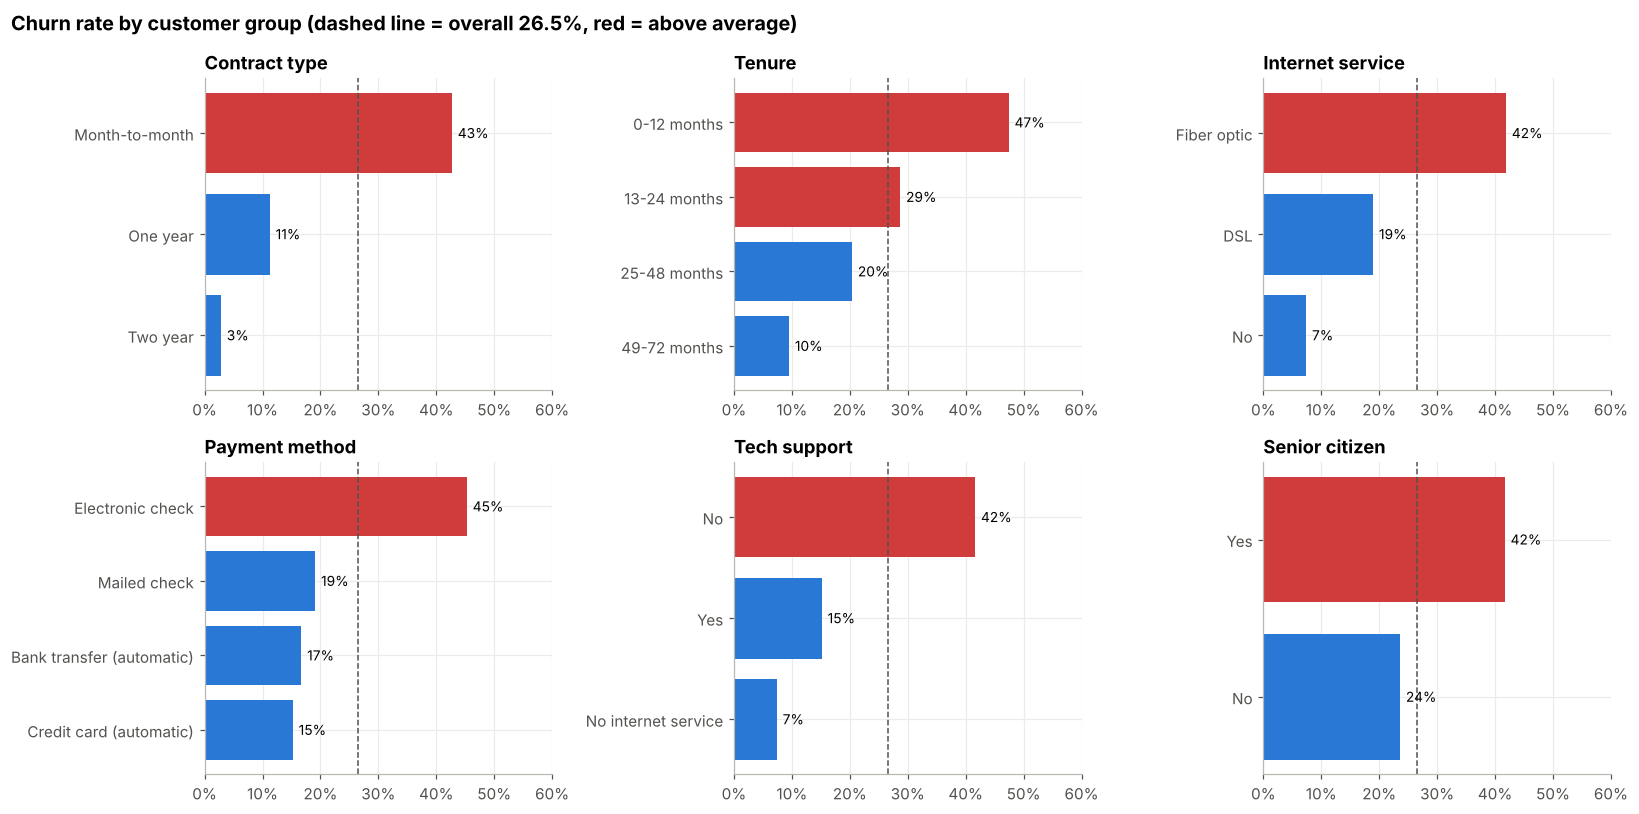

In [7]:
panels = [("Contract", "Contract type"), ("tenure_group", "Tenure"),
          ("InternetService", "Internet service"), ("PaymentMethod", "Payment method"),
          ("TechSupport", "Tech support"), ("SeniorCitizen", "Senior citizen")]
overall = df["Churn"].mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, title) in zip(axes.flat, panels):
    rates = df.groupby(col, observed=True)["Churn"].mean().sort_values()
    colors = [RED if r > overall else BLUE for r in rates]
    ax.barh(rates.index.astype(str), rates.values, color=colors)
    ax.axvline(overall, color=MUTED, ls="--", lw=1)
    for i, v in enumerate(rates.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
    ax.set_title(title); ax.set_xlim(0, 0.6)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
fig.suptitle("Churn rate by customer group (dashed line = overall 26.5%, red = above average)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG / "01_churn_by_group.png"); plt.show()

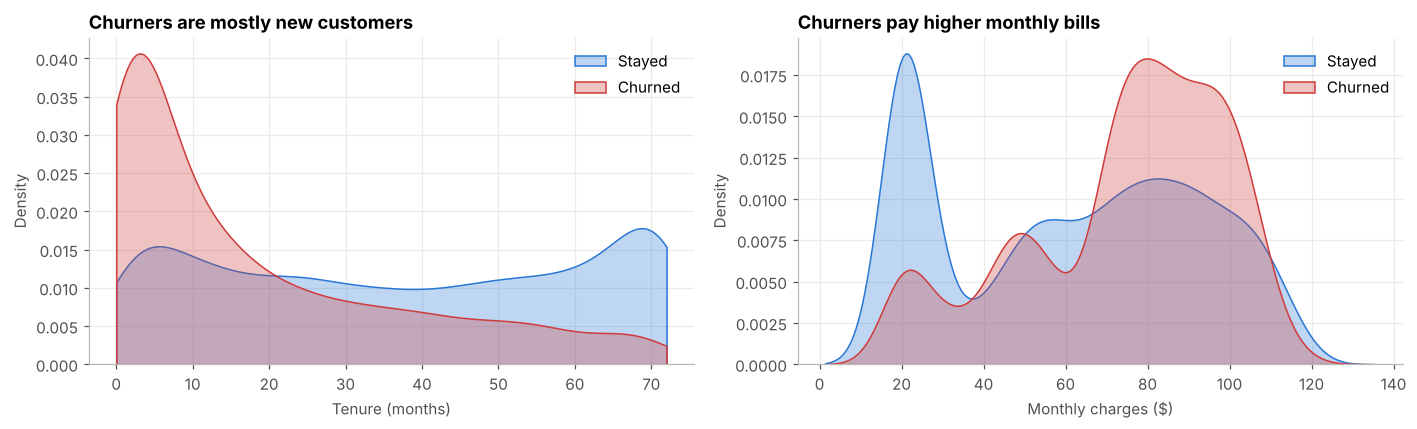

         tenure  MonthlyCharges
Churn                          
Stayed     38.0          64.425
Churned    10.0          79.650


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for churn, color, label in [(0, BLUE, "Stayed"), (1, RED, "Churned")]:
    sub = df[df["Churn"] == churn]
    sns.kdeplot(sub["tenure"], ax=axes[0], color=color, fill=True, alpha=0.3, label=label, clip=(0, 72))
    sns.kdeplot(sub["MonthlyCharges"], ax=axes[1], color=color, fill=True, alpha=0.3, label=label)
axes[0].set_title("Churners are mostly new customers"); axes[0].set_xlabel("Tenure (months)")
axes[1].set_title("Churners pay higher monthly bills"); axes[1].set_xlabel("Monthly charges ($)")
for ax in axes: ax.legend(frameon=False); ax.set_ylabel("Density")
plt.tight_layout(); plt.savefig(IMG / "02_tenure_and_charges.png"); plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median().rename(index={0: "Stayed", 1: "Churned"}))

**What the data says**
- **Contract is the biggest signal.** Month-to-month customers churn at ~43%, versus ~11% on one-year and ~3% on two-year contracts. They can leave any month with no penalty.
- **The first year is the riskiest.** Nearly half (~47%) of customers in their first 12 months churn. After 4 years it drops below 10%.
- **Fiber optic users churn more (~42%)** despite it being the premium service. It could be price (fiber bills are higher) or service quality. This is worth investigating with the product team.
- **Electronic check payers churn ~45%**, much higher than automatic payments (~15–17%). Automatic payment means one less moment each month where the customer has to decide to pay.
- **No tech support → ~42% churn**, versus ~15% with it.
- Senior citizens churn more (~42% vs ~24%).

## 3. Prepare features for the models

Models need numbers, not text. Steps:
1. Drop `customerID` (an id has no predictive meaning) and `tenure_group` (made only for the charts; the model gets the exact `tenure`).
2. **One-hot encode** the text columns: each category becomes its own 0/1 column. `drop_first=True` removes one column per feature, because it can be inferred from the others.
3. Split into **train (80%)** and **test (20%)**. `stratify=y` keeps the same 26.5% churn rate in both parts.
4. **Scale** the numeric columns for Logistic Regression. The scaler is fitted **only on the training data**, so no information from the test set leaks into training.

In [9]:
X = df.drop(columns=["customerID", "Churn", "tenure_group"])
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Number of features after encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} customers ({y_train.mean():.1%} churn)")
print(f"Test:  {len(X_test):,} customers ({y_test.mean():.1%} churn)")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler().fit(X_train[num_cols])           # fit on train only
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

Number of features after encoding: 30
Train: 5,634 customers (26.5% churn)
Test:  1,409 customers (26.5% churn)


## 4. Train and compare models

| Model | Why |
|---|---|
| **Baseline** (always predicts "won't churn") | Shows why accuracy is misleading here |
| **Logistic Regression** | Simple, fast, and easy to explain: each feature gets a weight |
| **Random Forest** | Many decision trees voting together; captures non-linear patterns |

Both real models use `class_weight="balanced"`. Churners are only 26.5% of the data, so this tells the model to treat a missed churner as more costly than a false alarm.

**Metrics**
- **Recall:** of all customers who actually churned, how many did the model catch? *The most important one here.* A missed churner is lost revenue.
- **Precision:** of the customers the model flagged, how many really churned? Low precision = wasted offers.
- **F1:** a balance of precision and recall.
- **ROC-AUC:** how well the model *ranks* customers by risk (0.5 = random, 1.0 = perfect).

In [10]:
models = {
    "Baseline (always 'stay')": (DummyClassifier(strategy="most_frequent"), False),
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced",
                                               random_state=RANDOM_STATE), True),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                             class_weight="balanced", random_state=RANDOM_STATE,
                                             n_jobs=-1), False),
}

rows, probas = [], {}
for name, (model, use_scaled) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if use_scaled else (X_train, X_test)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    probas[name] = proba
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (always 'stay'),0.735,0.000,0.000,0.000,0.500
Logistic Regression,0.738,0.504,0.783,0.614,0.842
Random Forest,0.760,0.533,0.781,0.633,0.843


**Reading the table**
- The baseline has **~73% accuracy but 0% recall**: it never catches a single churner. This is exactly why accuracy is the wrong metric here.
- Both real models catch about 78% of churners (recall) and rank customers equally well (ROC-AUC 0.842 vs 0.843).
- Random Forest is slightly better on accuracy and precision, but the gap is small.
- **I choose Logistic Regression** as the final model: same recall, practically the same ROC-AUC, and much easier to explain to a business team, because each feature has a clear direction and weight.

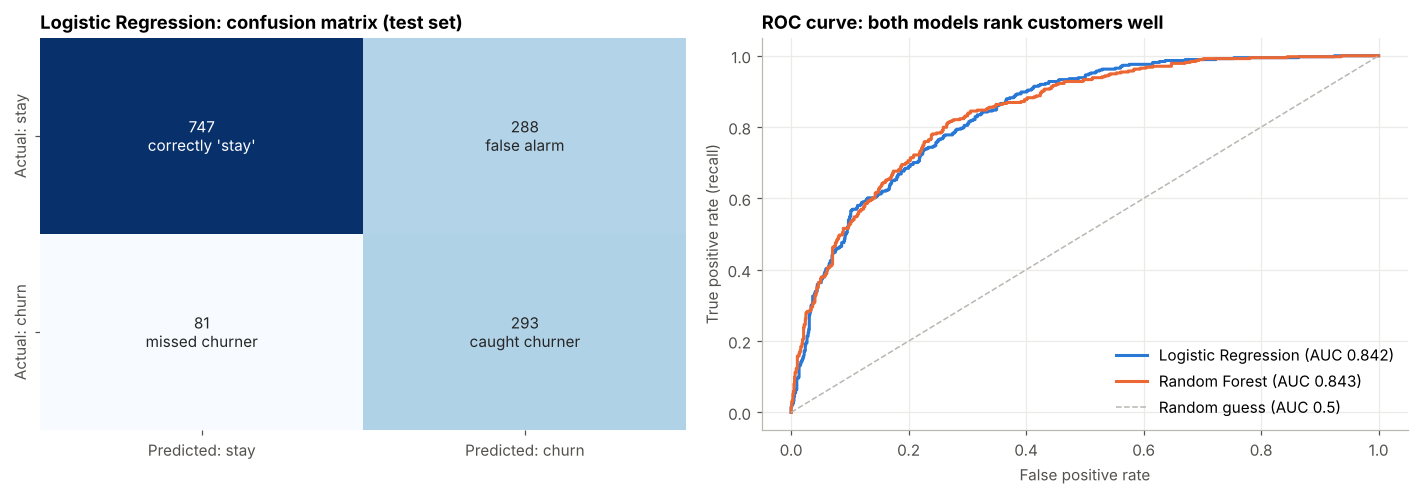

Out of 374 customers who actually churned, the model caught 293 (78%).
Out of 581 customers flagged as 'will churn', 293 really did (50%).


In [11]:
lr = models["Logistic Regression"][0]
rf = models["Random Forest"][0]
lr_pred = lr.predict(X_test_s)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Confusion matrix
cm = confusion_matrix(y_test, lr_pred)
labels = np.array([[f"{cm[0,0]}\ncorrectly 'stay'", f"{cm[0,1]}\nfalse alarm"],
                   [f"{cm[1,0]}\nmissed churner", f"{cm[1,1]}\ncaught churner"]])
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Predicted: stay", "Predicted: churn"],
            yticklabels=["Actual: stay", "Actual: churn"], annot_kws={"fontsize": 10})
axes[0].set_title("Logistic Regression: confusion matrix (test set)")
axes[0].grid(False)

# ROC curves
for name, color in [("Logistic Regression", BLUE), ("Random Forest", ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[1].plot(fpr, tpr, color=color, lw=2,
                 label=f"{name} (AUC {roc_auc_score(y_test, probas[name]):.3f})")
axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Random guess (AUC 0.5)")
axes[1].set_title("ROC curve: both models rank customers well")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].legend(frameon=False, loc="lower right")

plt.tight_layout(); plt.savefig(IMG / "03_confusion_matrix_and_roc.png"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Out of {tp + fn} customers who actually churned, the model caught {tp} ({tp / (tp + fn):.0%}).")
print(f"Out of {tp + fp} customers flagged as 'will churn', {tp} really did ({tp / (tp + fp):.0%}).")

### Choosing the threshold

By default a customer is flagged when predicted churn probability ≥ 0.5. Moving this threshold trades precision for recall. Which one is right depends on the cost of an offer versus the value of a saved customer.

In [12]:
lr_proba = probas["Logistic Regression"]
thresholds = pd.DataFrame([
    {"threshold": t,
     "customers_flagged": int((lr_proba >= t).sum()),
     "precision": precision_score(y_test, lr_proba >= t),
     "recall": recall_score(y_test, lr_proba >= t)}
    for t in [0.3, 0.4, 0.5, 0.6, 0.7]
]).round(3)
thresholds

,threshold,customers_flagged,precision,recall
0,0.3,806,0.431,0.928
1,0.4,695,0.466,0.866
2,0.5,581,0.504,0.783
3,0.6,489,0.540,0.706
4,0.7,374,0.604,0.604


- A **lower threshold** (0.3) catches more churners but flags many customers who would have stayed. Good when the offer is cheap (an email, a small discount).
- A **higher threshold** (0.7) flags fewer customers, and more of them are real churners. Good when the offer is expensive (a big discount, a personal call).

## 5. What drives churn?

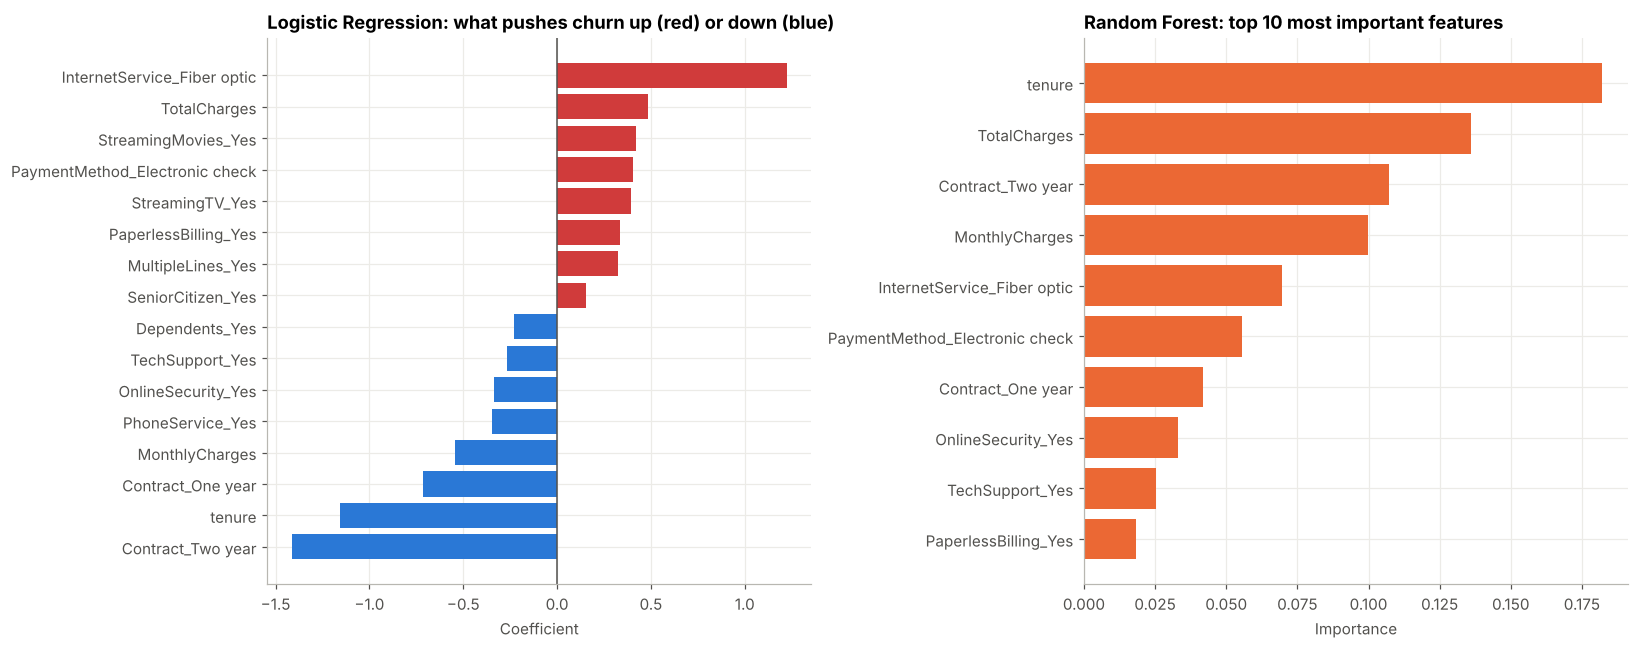

In [13]:
coefs = pd.Series(lr.coef_[0], index=X_train.columns).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])

rf_imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top.index, top.values, color=[BLUE if v < 0 else RED for v in top.values])
axes[0].axvline(0, color=MUTED, lw=1)
axes[0].set_title("Logistic Regression: what pushes churn up (red) or down (blue)")
axes[0].set_xlabel("Coefficient")

axes[1].barh(rf_imp.index, rf_imp.values, color=ORANGE)
axes[1].set_title("Random Forest: top 10 most important features")
axes[1].set_xlabel("Importance")
plt.tight_layout(); plt.savefig(IMG / "04_churn_drivers.png"); plt.show()

**How to read the left chart:** red bars increase the chance of churn, blue bars decrease it. Numeric features were scaled, so their size is comparable with the others. Text features are compared to the category that was dropped (for example, `Contract_Two year` is compared with month-to-month).

**Both models agree on the main drivers**
- **Contract:** two-year and one-year contracts strongly reduce churn (the biggest blue bars).
- **Tenure:** the longer someone stays, the less likely they leave.
- **Fiber optic internet** is the biggest push *towards* churn.
- **Electronic check** payment increases churn.
- **Online security and tech support** reduce churn.

**A surprise worth explaining:** in the EDA, churners pay *higher* monthly bills, but Logistic Regression gives `MonthlyCharges` a *negative* weight. The reason is **multicollinearity**: the monthly bill is mostly the sum of the services a customer has (fiber, streaming, extra lines), and those services are already in the model. Once the model knows a customer has fiber, the bill itself adds little, and the weights get shared out in ways that are hard to read on their own. So I don't interpret the `MonthlyCharges` weight by itself; the Random Forest chart and the EDA show more clearly that bills do matter.

Also, coefficients show *association*, not proof of cause. For example, two-year contracts may reduce churn partly because loyal customers choose them in the first place.

## 6. Who should the retention team call?

A team can't call every customer. The model **ranks** customers by churn probability, so the question becomes: *if we contact the top X% riskiest customers, what share of all churners do we reach?*

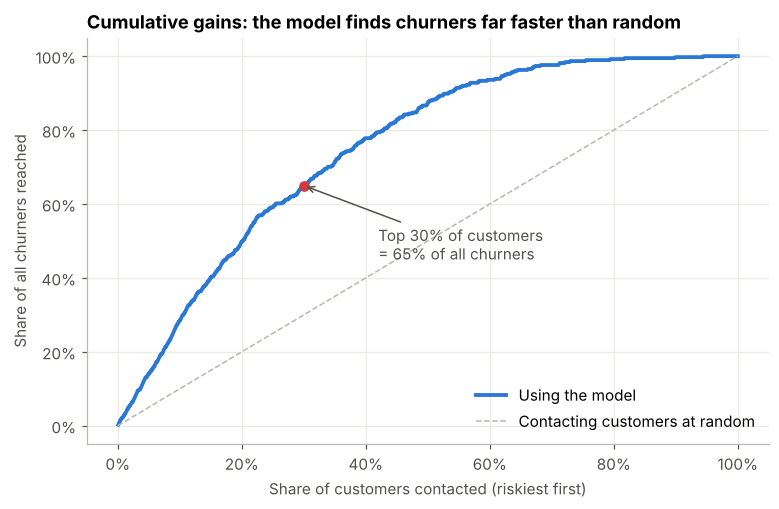

Contact top 10% riskiest -> reach 28% of churners (random would reach 10%)
Contact top 20% riskiest -> reach 50% of churners (random would reach 20%)
Contact top 30% riskiest -> reach 65% of churners (random would reach 30%)
Contact top 40% riskiest -> reach 78% of churners (random would reach 40%)
Contact top 50% riskiest -> reach 87% of churners (random would reach 50%)


In [14]:
ranked = pd.DataFrame({"proba": lr_proba, "churn": y_test.values}).sort_values("proba", ascending=False)
ranked["pct_customers"] = np.arange(1, len(ranked) + 1) / len(ranked)
ranked["pct_churners_caught"] = ranked["churn"].cumsum() / ranked["churn"].sum()

checkpoints = {}
for p in [0.1, 0.2, 0.3, 0.4, 0.5]:
    checkpoints[p] = ranked.loc[ranked["pct_customers"] <= p, "pct_churners_caught"].iloc[-1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(ranked["pct_customers"], ranked["pct_churners_caught"], color=BLUE, lw=2.5, label="Using the model")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Contacting customers at random")
p30 = checkpoints[0.3]
ax.scatter([0.3], [p30], color=RED, zorder=3)
ax.annotate(f"Top 30% of customers\n= {p30:.0%} of all churners", xy=(0.3, p30), xytext=(0.42, 0.45),
            arrowprops=dict(arrowstyle="->", color=MUTED), color=MUTED, fontsize=10)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of customers contacted (riskiest first)")
ax.set_ylabel("Share of all churners reached")
ax.set_title("Cumulative gains: the model finds churners far faster than random")
ax.legend(frameon=False, loc="lower right")
plt.savefig(IMG / "05_cumulative_gains.png"); plt.show()

for p, v in checkpoints.items():
    print(f"Contact top {p:.0%} riskiest -> reach {v:.0%} of churners (random would reach {p:.0%})")

In [15]:
risk = X_test.copy()
risk["customerID"] = df.loc[X_test.index, "customerID"]
risk["Contract"] = df.loc[X_test.index, "Contract"]
risk["churn_probability"] = lr_proba.round(3)
risk["risk_level"] = pd.cut(risk["churn_probability"], bins=[0, 0.4, 0.7, 1.0],
                            labels=["Low", "Medium", "High"], include_lowest=True)
risk["actually_churned"] = y_test.values

summary = risk.groupby("risk_level", observed=True).agg(
    customers=("customerID", "count"),
    actual_churn_rate=("actually_churned", "mean"),
    avg_monthly_bill=("MonthlyCharges", "mean"),
)
summary["actual_churn_rate"] = (summary["actual_churn_rate"] * 100).round(1)
summary.round(1)

,customers,actual_churn_rate,avg_monthly_bill
risk_level,,,
Low,714,7.0,54.7
Medium,323,30.7,66.9
High,372,60.5,79.7


The risk levels separate customers well: the actual churn rate in the **High** group is many times higher than in the **Low** group. This is the list the retention team would work from.

## 7. Recommendations

| Finding | Action |
|---|---|
| Month-to-month customers churn ~43% | Offer a discount for switching to a 1-year contract, targeted at High-risk month-to-month customers |
| First 12 months are the riskiest (~47%) | Onboarding programme: check-in call in month 1 and month 3, welcome offer |
| Electronic check payers churn ~45% | Small incentive to switch to automatic payment (bank / card) |
| No tech support / online security → ~42% churn | Free 3-month trial of tech support for High-risk customers |
| Fiber optic users churn ~42% | Investigate price and service quality with the product team |
| Model ranking | Retention team contacts the **top 30% riskiest** first; that reaches most churners at a fraction of the effort |

### Limitations
- One snapshot in time: we don't know *when* in the month customers left, or their history before.
- No data on competitor offers, complaints or network quality, which are likely real causes.
- IBM sample data: patterns are realistic, but a real company would retrain on its own data.
- Coefficients show association, not cause; an offer should be tested with an A/B test before rolling it out.

### Next steps
- A/B test the contract-upgrade offer on High-risk customers.
- Add customer-service data (complaints, call counts).
- Try gradient boosting (XGBoost) and tune the threshold using the real cost of an offer.

In [16]:
comparison.to_csv(OUT / "model_comparison.csv")
(risk[["customerID", "Contract", "MonthlyCharges", "tenure", "churn_probability", "risk_level", "actually_churned"]]
     .sort_values("churn_probability", ascending=False)
     .to_csv(OUT / "test_customers_risk_scores.csv", index=False))
churn_by_contract = churn_rate("Contract")
churn_by_contract.to_csv(OUT / "churn_rate_by_contract.csv")
print("Saved model_comparison.csv, test_customers_risk_scores.csv, churn_rate_by_contract.csv")

Saved model_comparison.csv, test_customers_risk_scores.csv, churn_rate_by_contract.csv
